In [7]:
import kagglehub
import os
import pandas as pd

# Point to the cached dataset directory
cardio_path = kagglehub.dataset_download("sulianova/cardiovascular-disease-dataset")
# Note: This CSV uses semicolon ';' as separator
df= pd.read_csv(os.path.join(cardio_path, "cardio_train.csv"), sep=";")


In [17]:
df.head()

df.describe

null_data = df.isnull().sum()

clinical_cols = [c for c in df.columns if c not in ['id', 'age', 'gender', 'cardio']]
print("Duplicate clinical profiles:", df.duplicated(subset=clinical_cols).sum())
print("Duplicate full rows (without id):", df.drop(columns=['id']).duplicated().sum())

Duplicate clinical profiles: 24770
Duplicate full rows (without id): 24


In [18]:
# 1. Drop 'id' and the 24 exact duplicate rows
df_clean = df.drop(columns=['id']).drop_duplicates().copy()

# 2. Convert age from days to years
df_clean['age'] = (df_clean['age'] / 365.25).round(1)

# 3. Filter out impossible blood pressure & height/weight entry errors
df_clean = df_clean[
    (df_clean['ap_hi'] >= 70) & (df_clean['ap_hi'] <= 250) &
    (df_clean['ap_lo'] >= 40) & (df_clean['ap_lo'] <= 160) &
    (df_clean['ap_hi'] > df_clean['ap_lo']) &
    (df_clean['height'] >= 130) & (df_clean['height'] <= 220) &
    (df_clean['weight'] >= 35) & (df_clean['weight'] <= 200)
].copy()

print("Clean shape:", df_clean.shape)
print("\nCorrelations with cardio:\n", df_clean.corr()['cardio'].sort_values(ascending=False))

Clean shape: (68539, 12)

Correlations with cardio:
 cardio         1.000000
ap_hi          0.428127
ap_lo          0.340535
age            0.239491
cholesterol    0.221364
weight         0.180024
gluc           0.089440
gender         0.007009
alco          -0.008569
height        -0.012503
smoke         -0.016345
active        -0.037551
Name: cardio, dtype: float64


In [20]:
df_clean['bmi'] = (df_clean['weight'] / ((df_clean['height'] / 100) ** 2)).round(2)
df_clean['pulse_pressure'] = df_clean['ap_hi'] - df_clean['ap_lo']
df_clean['map'] = (df_clean['ap_lo'] + (df_clean['pulse_pressure'] / 3)).round(2)

# 2. Drop gender and everything below it (including height)
cols_to_drop = ['gender', 'alco', 'height', 'smoke', 'active']
df_clean = df_clean.drop(columns=cols_to_drop)

print(df_clean.corr()['cardio'].sort_values(ascending=False))

cardio            1.000000
ap_hi             0.428127
map               0.409687
ap_lo             0.340535
pulse_pressure    0.337054
age               0.239491
cholesterol       0.221364
bmi               0.191387
weight            0.180024
gluc              0.089440
Name: cardio, dtype: float64


<Axes: >

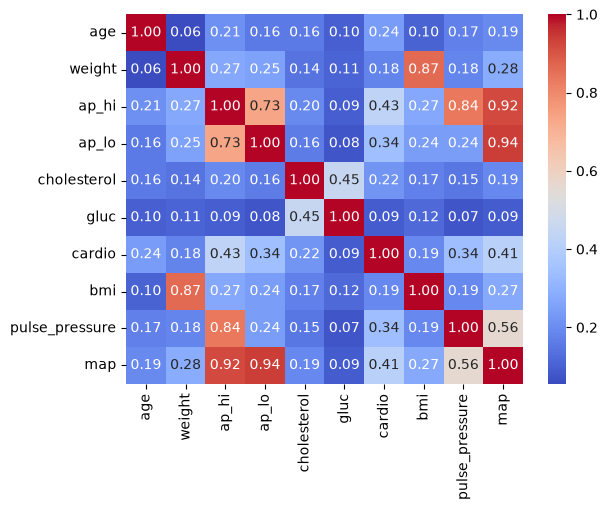

In [21]:
import seaborn as sns


sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f")


In [22]:
df_clean = df_clean.drop(columns=['weight', 'ap_lo'])

In [25]:
from sklearn.preprocessing import StandardScaler

cols_to_scale = ['trestbps', 'chol', 'thalach', 'oldpeak']

scaler = StandardScaler()

# Fit ONLY on X_train to prevent data leakage, then transform both
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

In [26]:
X_train.corrwith(y_train).sort_values(ascending=False)

cp          0.432417
thalach     0.416169
slope       0.347017
restecg     0.139828
age        -0.027649
fbs        -0.034975
chol       -0.080770
trestbps   -0.146256
thal       -0.364020
ca         -0.407038
oldpeak    -0.434259
exang      -0.440170
dtype: float64

<Axes: >

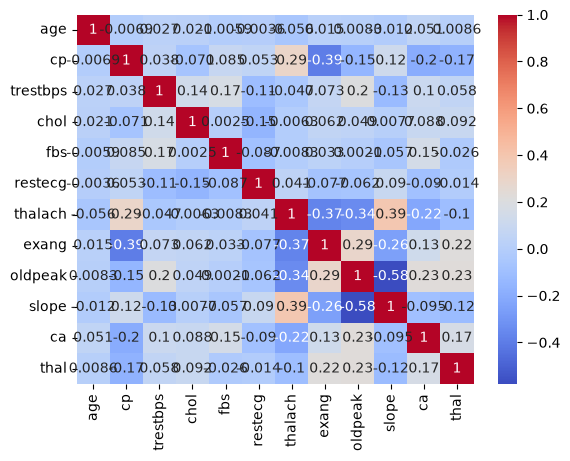

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(X_train.corr(), annot=True, cmap='coolwarm')

In [28]:
clinical_cols = [col for col in X_train.columns if col != 'age']
print("Total rows:", len(df))
print("Unique patient profiles:", df[clinical_cols].drop_duplicates().shape[0])

Total rows: 26083
Unique patient profiles: 302


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score

# 1. Initialize the model (n_jobs=-1 uses all your CPU cores)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)

# 2. Train on the scaled training data
rf_model.fit(X_train, y_train)

# 3. Predict on the test data
y_pred = rf_model.predict(X_test)

# 4. Evaluate performance
print(classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(accuracy_score(y_test, y_pred))




              precision    recall  f1-score   support

           0       1.00      0.99      1.00      2337
           1       0.99      1.00      1.00      2880

    accuracy                           1.00      5217
   macro avg       1.00      1.00      1.00      5217
weighted avg       1.00      1.00      1.00      5217

Confusion Matrix:
 [[2321   16]
 [   0 2880]]
0.9969331033160821


Allah akbar 3la el data Leakage

In [30]:
# Keep only the 302 real unique clinical records and drop the corrupted 'age' column
df_clean = df.drop_duplicates(subset=clinical_cols).drop(columns=['age']).copy()
print("Clean dataset shape:", df_clean.shape)


Clean dataset shape: (302, 12)


In [32]:
x = df_clean.drop(columns=['target'])
y = df_clean['target']

X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(x, y, test_size=0.2, random_state=42)


In [33]:
rf_model_clean = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42, n_jobs=-1)

rf_model_clean.fit(X_train_clean, y_train_clean)

# 3. Predict on the test data
y_pred = rf_model_clean.predict(X_test_clean)

# 4. Evaluate performance
print(classification_report(y_test_clean, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test_clean, y_pred))
print(accuracy_score(y_test_clean, y_pred))


              precision    recall  f1-score   support

           0       0.88      0.79      0.84        29
           1       0.83      0.91      0.87        32

    accuracy                           0.85        61
   macro avg       0.86      0.85      0.85        61
weighted avg       0.86      0.85      0.85        61

Confusion Matrix:
 [[23  6]
 [ 3 29]]
0.8524590163934426
